In [433]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans

In [434]:
df_kmeans=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\sena\GESTION DE DATOS EN MODELOS DE INTELIGENCIA ARTIFICIAL\df_kmeans.csv')
df_kmeans.drop(columns='Unnamed: 0',inplace=True)
df_kmeans.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SpendingScore  1000 non-null   float64
 1   WebVisits      1000 non-null   float64
 2   Age            1000 non-null   float64
 3   ItemsInCart    1000 non-null   float64
dtypes: float64(4)
memory usage: 31.4 KB


In [435]:
#Se elige aleatoriamente con cualquier mecanismo el registro 30, el registro 51 y el registro 120, usando la función loc del dataframe:
indiceMuestra =[30,51,120]
muestras = pd.DataFrame (df_kmeans.loc[indiceMuestra], columns = df_kmeans.keys()).reset_index(drop =True)
muestras

,SpendingScore,WebVisits,Age,ItemsInCart
0,1.323076,0.651294,1.480359,1.637754
1,-0.632361,-1.564387,1.547098,0.710373
2,1.082934,-0.981313,0.946439,-0.448852


In [436]:
#Una vez escogidas las muestras, estas se eliminan de la data original df_kmeans, de los datos de muestra, para que estos no se integren con el resto de la información.
df_kmeans= df_kmeans.drop(indiceMuestra, axis = 0)

In [437]:
df_kmeans.info()

<class 'pandas.DataFrame'>
Index: 997 entries, 0 to 999
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SpendingScore  997 non-null    float64
 1   WebVisits      997 non-null    float64
 2   Age            997 non-null    float64
 3   ItemsInCart    997 non-null    float64
dtypes: float64(4)
memory usage: 38.9 KB


In [438]:
#En una variable X se guardan las columnas con valores del dataset original, con los cuales se va a entrenar el algoritmo; para esto se usa la función iloc sobre el
#dataset original iris_df. Estos datos corresponden a las variables de longitudes y anchos de los sépalos y los pétalos únicamente.
#El conjunto de datos no cuenta con una columna de variable dependiente o Y en aprendizaje no supervisado, todos son variables dependientes, en este caso es X.

X = df_kmeans.iloc[:, [0, 1, 2,3]].values
X

array([[-0.42652529, -1.68100213,  0.81295917, -1.60807774],
       [ 1.66613477,  0.65129357,  1.68057836,  1.63775391],
       [-0.42652529,  1.58421185,  0.1455598 ,  0.24668321],
       ...,
       [-0.97541973,  1.70082664,  1.2133988 ,  1.63775391],
       [ 0.63695769, -1.0979282 , -0.5885795 , -1.60807774],
       [-0.15207807,  1.58421185,  0.74621924, -1.60807774]],
      shape=(997, 4))

In [439]:
df_kmeans.describe()

,SpendingScore,WebVisits,Age,ItemsInCart
count,997.000000,997.000000,997.000000,997.000000
mean,-0.001779,0.001900,-0.003986,-0.001905
std,1.000338,1.000081,0.999248,1.000305
min,-1.627232,-1.681002,-1.723158,-1.608078
25%,-0.906808,-0.864699,-0.855539,-0.912542
50%,-0.049160,-0.048395,0.012080,0.014838
75%,0.842793,0.884523,0.812959,0.942219
max,1.734747,1.700827,1.680578,1.637754


In [440]:
inercia =[] # suma de cuadrados
for i in range (1,20): 
        algoritmo = KMeans (n_clusters  = i, max_iter =300).fit(X)
        inercia.append(algoritmo.inertia_)

<function matplotlib.pyplot.show(close=None, block=None)>

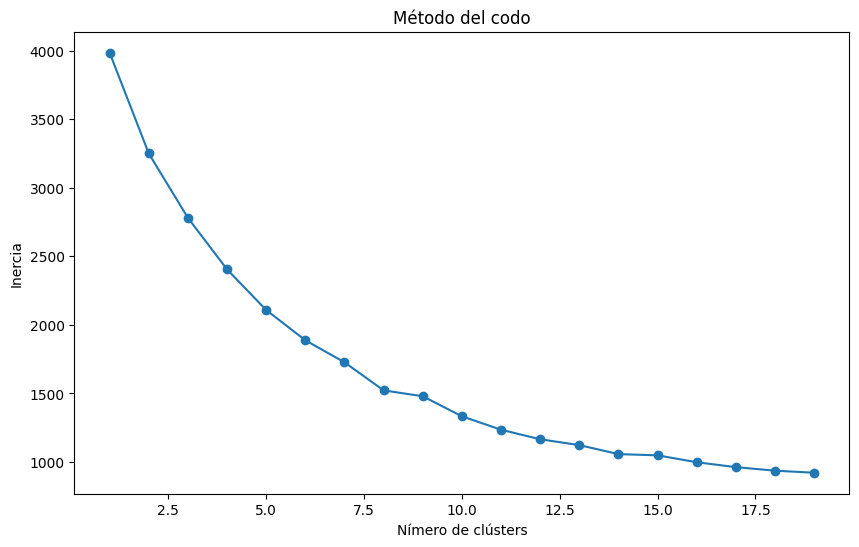

In [441]:
plt.figure(figsize =[10,6])
plt.title('Método del codo')
plt.xlabel('Nímero de clústers')
plt.ylabel('Inercia')
plt.plot ( list(range(1,20)), inercia, marker='o')
plt.show


In [442]:
#n_clusters = 6 porque según el gráfico anterior, el codo está entre 5 y 7.5.
algoritmo = KMeans( n_clusters=6, init ='k-means++', max_iter=300, n_init =10)

In [443]:
algoritmo.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",6
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [444]:
centroides, etiquetas = algoritmo.cluster_centers_, algoritmo.labels_

In [445]:
centroides

array([[-0.89492418, -0.53543336, -0.57767429,  0.87554415],
       [ 0.78069751,  1.02850006, -0.47821626, -0.46957573],
       [-0.4688359 ,  0.92274688,  0.61125625,  0.70006921],
       [ 0.93275614, -0.90139559, -0.91434507,  0.03267233],
       [-0.90204321, -0.21748657,  0.08586464, -1.06066565],
       [ 0.67147536, -0.60699435,  1.0819788 ,  0.0520478 ]])

In [446]:
etiquetas

array([4, 5, 2, 0, 2, 0, 3, 5, 4, 3, 4, 3, 3, 0, 1, 4, 3, 4, 1, 4, 2, 5,
       5, 3, 1, 2, 0, 1, 5, 4, 2, 0, 1, 2, 1, 5, 5, 2, 5, 1, 1, 5, 1, 3,
       3, 0, 1, 0, 3, 1, 1, 4, 0, 0, 4, 4, 4, 5, 4, 2, 4, 0, 1, 4, 5, 1,
       1, 0, 3, 1, 0, 3, 1, 2, 5, 4, 3, 5, 3, 4, 2, 3, 4, 1, 1, 0, 1, 3,
       5, 3, 5, 1, 3, 4, 2, 2, 3, 1, 0, 0, 4, 1, 2, 3, 3, 2, 1, 4, 0, 5,
       0, 0, 4, 1, 4, 1, 2, 2, 2, 3, 0, 3, 4, 4, 4, 5, 3, 0, 4, 5, 5, 4,
       1, 4, 4, 3, 2, 2, 5, 0, 1, 0, 3, 1, 1, 5, 4, 1, 3, 0, 2, 2, 3, 2,
       4, 5, 5, 2, 1, 3, 2, 5, 0, 5, 5, 1, 0, 4, 1, 0, 2, 3, 2, 3, 2, 4,
       5, 5, 4, 2, 4, 5, 5, 0, 2, 0, 0, 3, 4, 4, 0, 0, 5, 1, 5, 1, 5, 0,
       3, 2, 3, 2, 5, 4, 5, 0, 1, 4, 4, 4, 2, 5, 5, 5, 5, 2, 0, 5, 3, 3,
       5, 4, 2, 1, 5, 4, 1, 5, 2, 2, 4, 1, 3, 2, 1, 4, 0, 1, 3, 0, 0, 1,
       0, 5, 3, 1, 1, 1, 3, 4, 0, 5, 1, 4, 4, 3, 4, 4, 3, 4, 1, 1, 2, 1,
       3, 1, 4, 1, 5, 5, 4, 2, 0, 3, 4, 0, 2, 0, 4, 5, 1, 4, 1, 4, 1, 1,
       1, 0, 5, 5, 2, 1, 3, 5, 1, 3, 4, 5, 3, 5, 4,

In [447]:
len(etiquetas)

997

In [448]:
Xmuestras = muestras.iloc[:, [0, 1, 2, 3]].values
YMuestraPrediccion = algoritmo.predict (Xmuestras )

In [449]:
print (YMuestraPrediccion)

[5 5 5]


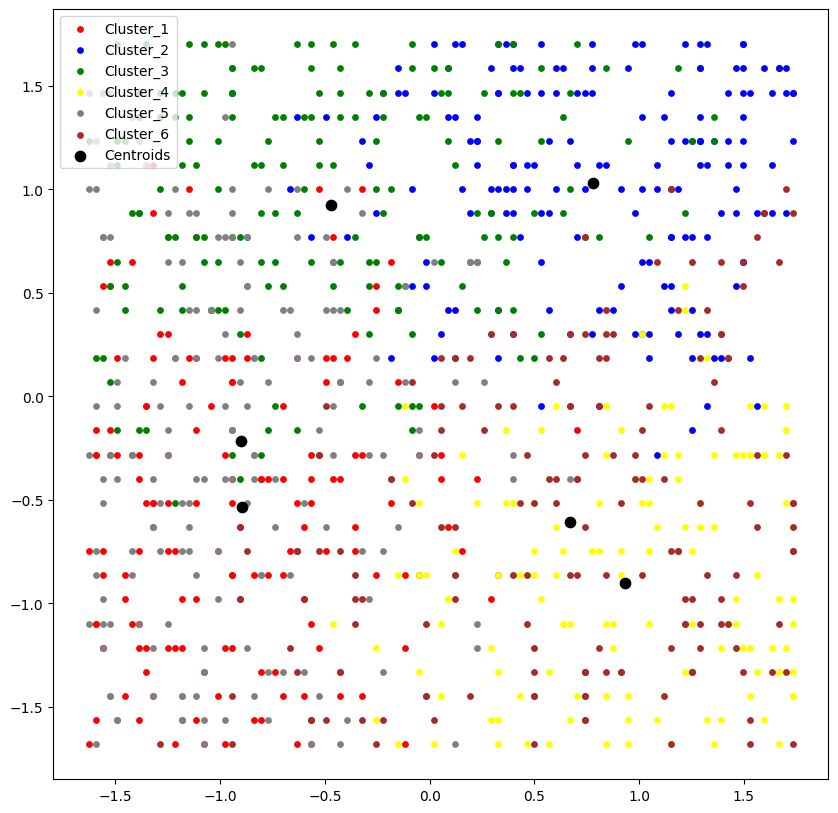

In [450]:
#Aplicando k-means al dataset / creacion del clasificador con k-means
plt.figure(figsize =[10,10])
plt.scatter(X[etiquetas == 0,0], X[etiquetas==0,1], s = 15, c= 'red', label = 'Cluster_1')
plt.scatter(X[etiquetas== 1,0], X[etiquetas==1,1], s = 15, c= 'blue', label = 'Cluster_2')
plt.scatter(X[etiquetas == 2,0], X[etiquetas==2,1], s = 15, c= 'green', label = 'Cluster_3')
plt.scatter(X[etiquetas == 3,0], X[etiquetas==3,1], s = 15, c= 'yellow', label = 'Cluster_4')
plt.scatter(X[etiquetas == 4,0], X[etiquetas==4,1], s = 15, c= 'gray', label = 'Cluster_5')
plt.scatter(X[etiquetas == 5,0], X[etiquetas==5,1], s = 15, c= 'brown', label = 'Cluster_6')
plt.scatter(centroides[:,0], centroides[:,1], s = 55, c = 'black', label = 'Centroids')
plt.legend()
plt.show()

Recuperando los valores reales del dataset.

In [451]:
ds=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\sena\GESTION DE DATOS EN MODELOS DE INTELIGENCIA ARTIFICIAL\quantum_customer_data.csv')
ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               1000 non-null   int64  
 1   CustomerID               1000 non-null   str    
 2   Age                      1000 non-null   int64  
 3   AnnualIncome             1000 non-null   int64  
 4   SpendingScore            1000 non-null   int64  
 5   WebVisits                1000 non-null   int64  
 6   DaysSinceLastPurchase    1000 non-null   int64  
 7   EmailsOpened             1000 non-null   int64  
 8   AdClicks                 1000 non-null   int64  
 9   SocialMediaInteractions  1000 non-null   int64  
 10  AvgSessionDuration       1000 non-null   float64
 11  ItemsInCart              1000 non-null   int64  
dtypes: float64(1), int64(10), str(1)
memory usage: 93.9 KB


In [452]:
#Se elige aleatoriamente con cualquier mecanismo el registro 30, el registro 51 y el registro 120, usando la función loc del dataframe:
indiceMuestra_nss=[30,51,120]
muestras_nss = pd.DataFrame (ds.loc[indiceMuestra], columns = ds.keys()).reset_index(drop =True)
muestras

,SpendingScore,WebVisits,Age,ItemsInCart
0,1.323076,0.651294,1.480359,1.637754
1,-0.632361,-1.564387,1.547098,0.710373
2,1.082934,-0.981313,0.946439,-0.448852


In [453]:
#Una vez escogidas las muestras, estas se eliminan de la data original df_kmeans, de los datos de muestra, para que estos no se integren con el resto de la información.
ds= ds.drop(indiceMuestra, axis = 0)
ds.info()

<class 'pandas.DataFrame'>
Index: 997 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               997 non-null    int64  
 1   CustomerID               997 non-null    str    
 2   Age                      997 non-null    int64  
 3   AnnualIncome             997 non-null    int64  
 4   SpendingScore            997 non-null    int64  
 5   WebVisits                997 non-null    int64  
 6   DaysSinceLastPurchase    997 non-null    int64  
 7   EmailsOpened             997 non-null    int64  
 8   AdClicks                 997 non-null    int64  
 9   SocialMediaInteractions  997 non-null    int64  
 10  AvgSessionDuration       997 non-null    float64
 11  ItemsInCart              997 non-null    int64  
dtypes: float64(1), int64(10), str(1)
memory usage: 101.3 KB


In [454]:
ds['Labels']=0
ds.info()

<class 'pandas.DataFrame'>
Index: 997 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               997 non-null    int64  
 1   CustomerID               997 non-null    str    
 2   Age                      997 non-null    int64  
 3   AnnualIncome             997 non-null    int64  
 4   SpendingScore            997 non-null    int64  
 5   WebVisits                997 non-null    int64  
 6   DaysSinceLastPurchase    997 non-null    int64  
 7   EmailsOpened             997 non-null    int64  
 8   AdClicks                 997 non-null    int64  
 9   SocialMediaInteractions  997 non-null    int64  
 10  AvgSessionDuration       997 non-null    float64
 11  ItemsInCart              997 non-null    int64  
 12  Labels                   997 non-null    int64  
dtypes: float64(1), int64(11), str(1)
memory usage: 109.0 KB


In [455]:
for i in range(0,ds.shape[0]):
    ds.iloc[i,12]=etiquetas[i]

cluster0=ds[ds['Labels']==0]
cluster1=ds[ds['Labels']==1]
cluster2=ds[ds['Labels']==2]
cluster3=ds[ds['Labels']==3]
cluster4=ds[ds['Labels']==4]
cluster5=ds[ds['Labels']==5]


Cluster0.

In [456]:
print('SpendingScore',cluster0['SpendingScore'].mean(),'WebVisits',cluster0['WebVisits'].mean(),'Age',cluster0['Age'].mean(),'ItemsInCart',cluster0['ItemsInCart'].mean())

SpendingScore 22.34640522875817 WebVisits 9.823529411764707 Age 35.16339869281046 ItemsInCart 10.712418300653594


Cluster1.

In [457]:
print('SpendingScore',cluster1['SpendingScore'].mean(),'WebVisits',cluster1['WebVisits'].mean(),'Age',cluster1['Age'].mean(),'ItemsInCart',cluster1['ItemsInCart'].mean())

SpendingScore 71.18994413407822 WebVisits 23.23463687150838 Age 36.6536312849162 ItemsInCart 4.910614525139665


Cluster2.

In [458]:
print('SpendingScore',cluster2['SpendingScore'].mean(),'WebVisits',cluster2['WebVisits'].mean(),'Age',cluster2['Age'].mean(),'ItemsInCart',cluster2['ItemsInCart'].mean())

SpendingScore 34.766666666666666 WebVisits 22.32777777777778 Age 52.977777777777774 ItemsInCart 9.955555555555556


Cluster3.

In [459]:
print('SpendingScore',cluster3['SpendingScore'].mean(),'WebVisits',cluster3['WebVisits'].mean(),'Age',cluster3['Age'].mean(),'ItemsInCart',cluster3['ItemsInCart'].mean())

SpendingScore 75.62237762237763 WebVisits 6.685314685314685 Age 30.11888111888112 ItemsInCart 7.076923076923077


Cluster4.

In [460]:
print('SpendingScore',cluster4['SpendingScore'].mean(),'WebVisits',cluster4['WebVisits'].mean(),'Age',cluster4['Age'].mean(),'ItemsInCart',cluster4['ItemsInCart'].mean())

SpendingScore 22.13888888888889 WebVisits 12.55 Age 45.105555555555554 ItemsInCart 2.361111111111111


Cluster5.

In [461]:
print('SpendingScore',cluster5['SpendingScore'].mean(),'WebVisits',cluster5['WebVisits'].mean(),'Age',cluster5['Age'].mean(),'ItemsInCart',cluster5['ItemsInCart'].mean())

SpendingScore 68.00617283950618 WebVisits 9.209876543209877 Age 60.03086419753087 ItemsInCart 7.160493827160494
